# PCS26/84 — DEEP LEARNING-BASED FAKE NEWS DETECTION

## Notebook 03 — LSTM and BiLSTM Text Classifiers

| | |
|---|---|
| **Project code** | PCS26/84 |
| **Project title** | DEEP LEARNING-BASED FAKE NEWS DETECTION |
| **Position** | Notebook 3 of 5 (01 audit → 02 ML → **03 LSTM/BiLSTM** → 04 transformer → 05 evaluation & explainability) |
| **Labels** | **Fake = 0, Real = 1** |


### Abstract
This notebook trains a unidirectional **LSTM** and a **bidirectional LSTM (BiLSTM)** on the *same marker-stripped input, the same eligible rows and the same saved split* as the frozen classical model of Notebook 02, so that classical and neural models can be compared fairly. It corrects the weaknesses of the first version (undefined variables, unseeded initialisation, unpacked padding, no test/curve/ROC evaluation, stale environment text) and adds an information-matched SVM that sees only the first 200 tokens, exactly like the networks.

### Research questions
* **RQ1** Do recurrent networks outperform a TF-IDF linear model on identical examples?
* **RQ2** Does reading the text in both directions (BiLSTM) help?
* **RQ3** Does limiting the classical model to the same 200-token window change the ML-vs-DL conclusion?
* **RQ4** Are differences larger than what chance on ~6 600 validation examples allows (paired tests)?

### Why deep learning for text, and how the models work
Bag-of-n-gram models ignore word order. Recurrent networks read a text token by token and carry a **hidden state** that summarises what has been read, so order and context can matter.

**Embedding.** Each token id indexes a trainable vector `eₜ ∈ ℝ⁶⁴`; padding id 0 maps to a zero vector and receives no gradient.

**LSTM.** At step *t* the cell computes gates from the input `eₜ` and previous hidden state `hₜ₋₁`:
`fₜ = σ(W_f[hₜ₋₁,eₜ]+b_f)`, `iₜ = σ(W_i[hₜ₋₁,eₜ]+b_i)`, `ĉₜ = tanh(W_c[hₜ₋₁,eₜ]+b_c)`, `cₜ = fₜ⊙cₜ₋₁ + iₜ⊙ĉₜ`, `oₜ = σ(W_o[hₜ₋₁,eₜ]+b_o)`, `hₜ = oₜ⊙tanh(cₜ)`.
The forget/input gates let the cell retain or overwrite information, which mitigates vanishing gradients over long sequences. The classifier uses the **final hidden state** `h_T` (the state after the *last real token*).

**BiLSTM.** Two LSTMs read the sequence left-to-right and right-to-left; the representation is `[h_T^→ ; h_1^←]` (dimension 128), so each direction contributes context the other lacks.

**Packed sequences (the padding fix).** Articles have different lengths and are padded to 200 tokens. The first version passed padded batches straight to the LSTM, so the "final" state was taken *after* a run of padding tokens, which both dilutes the representation and lets the amount of padding (i.e. article length) leak into the classifier. `pack_padded_sequence` tells the LSTM each sequence's true length, so `h_T` is the state at the last real token and padding is invisible.

**Output and loss.** `dropout(0.3)` → linear layer with 2 outputs → softmax; **cross-entropy** `L = −log p_θ(y | x)` averaged over the batch. **Optimiser:** Adam (learning rate 10⁻³) with gradient-norm clipping at 1.0. **Regularisation:** dropout, a modest model (embedding 64, hidden 64) and early stopping. **Early stopping:** training stops when validation loss has not improved by 0.001 for 2 epochs; the best-validation-loss weights are restored.

**Tokenisation and vocabulary.** Lower-cased regular-expression tokens (letters, digits, punctuation marks); vocabulary = the 20 000 most frequent training tokens (+ `<PAD>`, `<UNK>`); words outside it map to `<UNK>`. Sequences longer than **200 tokens are truncated at the end** (head truncation).

**Reproducibility.** `set_seed(42)` (Python, NumPy, PyTorch) is called *before each model is constructed* and the shuffling generator is seeded; the single-seed limitation is stated at the end.

In [27]:
from pathlib import Path
import copy
import datetime as dt
import json
import os
import platform
import sys
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
import torch.nn as nn
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

warnings.filterwarnings("default")


def find_project_root(marker="dataset"):
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise FileNotFoundError(
        f"No '{marker}/' folder found above {here}. Open the notebook from the project root or notebooks/.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "dataset" / "combined_fake_news_clean.csv"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
LEGACY_MODELS_DIR = PROJECT_ROOT / "models"              # read-only here
MODELS_DIR = PROJECT_ROOT / "models" / "phase1"
SRC_DIR = PROJECT_ROOT / "src"
for folder in (TABLES_DIR, FIGURES_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(SRC_DIR))
for needed in ("fakenews_utils.py", "fakenews_dl.py"):
    if not (SRC_DIR / needed).exists():
        raise FileNotFoundError(f"{SRC_DIR / needed} not found. Copy the delivered src/ folder into the project root.")
import fakenews_utils as fu
import fakenews_dl as dl

# ---- configuration (documented, fixed in advance) -----------------------------------
SEED = 42
MAX_LEN = 200                 # same as the original notebook (head truncation)
MAX_VOCAB = 20_000
EMBEDDING_DIM = 64
HIDDEN_SIZE = 64
DROPOUT = 0.3
BATCH_SIZE = 32
LEARNING_RATE = 1e-3
MAX_EPOCHS = int(os.environ.get("FN_MAX_EPOCHS", "6"))
PATIENCE = 2
MIN_IMPROVEMENT = 1e-3        # validation-loss improvement needed to reset patience

# ---- safety / control switches --------------------------------------------------------
OVERWRITE_PHASE1_MODELS = os.environ.get("FN_OVERWRITE_PHASE1", "0") == "1"
RUN_FINAL_TEST = True      # <<< final cell. Leave False until the DL model is frozen.
FINAL_DRYRUN = os.environ.get("FN_FINAL_DRYRUN", "0") == "1"   # developer smoke test on VALIDATION data

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Project root:", PROJECT_ROOT)
print("Device:", DEVICE)

Project root: C:\Users\mi\Desktop\Fake-news detection
Device: cpu


## 1. Environment report
Versions are printed at run time (no stale text). Record them in the project report.

In [3]:
print("Python:", platform.python_version(), "|", platform.platform())
print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available(),
      f"| CUDA build: {torch.version.cuda}")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("numpy:", np.__version__, "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
print("CPU threads used by torch:", torch.get_num_threads())
try:
    import psutil
    vm = psutil.virtual_memory()
    print(f"RAM: total {vm.total / 1e9:.1f} GB, available {vm.available / 1e9:.1f} GB")
except ImportError:
    print("psutil not installed - RAM report skipped (pip install psutil to enable).")

Python: 3.13.4 | Windows-11-10.0.22631-SP0
torch: 2.14.1+cpu | CUDA available: False | CUDA build: None
numpy: 2.5.3 | pandas: 3.0.6 | scikit-learn: 1.9.1
CPU threads used by torch: 4
RAM: total 8.4 GB, available 0.6 GB


**Interpretation (resources).** The printed device and memory define what is feasible: on a CPU-only laptop the two small recurrent models (≈ 1.3 M parameters) train in minutes per epoch, whereas a 66 M-parameter transformer (Notebook 04) does not. Recording versions and the device makes the run reproducible and explains timing differences between machines.

## 2. Load data and the existing split manifest (explicit, verified)
The saved manifest is loaded (never regenerated) and its integrity is computed from the data.

In [4]:
df = pd.read_csv(DATA_PATH)
MANIFEST_PATH = TABLES_DIR / "data_split_manifest.csv"
assert MANIFEST_PATH.exists(), "Split manifest not found. Run Notebook 01 first."
manifest = pd.read_csv(MANIFEST_PATH)

train_idx = manifest.loc[manifest["partition"] == "train", "row_index"].astype(int).to_numpy()
val_idx = manifest.loc[manifest["partition"] == "validation", "row_index"].astype(int).to_numpy()
test_idx = manifest.loc[manifest["partition"] == "test", "row_index"].astype(int).to_numpy()
train_df, val_df, test_df = df.iloc[train_idx].copy(), df.iloc[val_idx].copy(), df.iloc[test_idx].copy()

keys = fu.article_key(df["title"], df["text"])
g_tr, g_va, g_te = (set(keys.iloc[i]) for i in (train_idx, val_idx, test_idx))
INTEGRITY = pd.DataFrame([
    ("Partitions cover every row exactly once",
     set(manifest["row_index"]) == set(range(len(df))) and manifest["row_index"].is_unique),
    ("No identical title+body group across train/validation/test",
     g_tr.isdisjoint(g_va) and g_tr.isdisjoint(g_te) and g_va.isdisjoint(g_te)),
    ("Label values are exactly {0, 1}; mapping Fake=0, Real=1", set(df["label"].unique()) == {0, 1} and fu.LABEL_MAP == {"Fake": 0, "Real": 1}),
    ("Both labels in every partition", all(set(p["label"].unique()) == {0, 1} for p in (train_df, val_df, test_df))),
], columns=["Check", "Passed"])
display(INTEGRITY)
assert INTEGRITY["Passed"].all()

registry = fu.HashRegistry(TABLES_DIR / "phase1_hash_registry.json", PROJECT_ROOT)
print("Manifest hash:", registry.check(MANIFEST_PATH), "| clean CSV hash:", registry.check(DATA_PATH))
print(f"train={len(train_df):,}  validation={len(val_df):,}  test={len(test_df):,}  (test is not scored before the final cell)")

,Check,Passed
0,Partitions cover every row exactly once,True
1,No identical title+body group across train/val...,True
2,"Label values are exactly {0, 1}; mapping Fake=...",True
3,Both labels in every partition,True


Manifest hash: verified | clean CSV hash: verified
train=30,796  validation=6,652  test=6,610  (test is not scored before the final cell)


## 3. Input pipeline: reuse the frozen preprocessing from Notebook 02
The neural models receive **exactly the same text** as the frozen ML model: the same input variant and the same marker-removal rules (selected in Notebook 02 on training data). The configuration file written by Notebook 02 is verified by hash and read here. A row is *eligible* if its input is non-empty under every Notebook-02 variant, so ML and DL are compared on identical examples.

In [5]:
ML_CONFIG_PATH = MODELS_DIR / "ml_selected_config.json"
ML_BUNDLE_PATH = MODELS_DIR / "ml_selected_pipeline.joblib"
if not (ML_CONFIG_PATH.exists() and ML_BUNDLE_PATH.exists()):
    raise FileNotFoundError(
        "Frozen ML model not found in models/phase1/. Run Notebook 02 through section B10 first - "
        "it selects the input variant and marker rules this notebook must reuse.")

ml_cfg = json.loads(ML_CONFIG_PATH.read_text())
assert fu.sha256_file(ML_BUNDLE_PATH) == ml_cfg["bundle_sha256"], "Frozen ML bundle changed after freezing."
ml_bundle = fu.load_bundle(ML_BUNDLE_PATH)
ML_VARIANT = ml_cfg["signature"]["variant"]
ACTIVE_RULES = ml_cfg["signature"]["active_rules"]
ml_builder = ml_bundle["pipeline"].named_steps["text"]       # the frozen text builder
print(f"Input variant: {ML_VARIANT} ({ml_cfg['input_description']})")
print("Frozen marker rules:", ACTIVE_RULES)
print("Frozen ML model:", ml_cfg["signature"]["model"])

y_train_all = train_df["label"].to_numpy(int)
y_val_all = val_df["label"].to_numpy(int)

# eligibility under every Notebook-02 variant (same definition as Notebook 02)
empty_masks = {}
TEXTS = {}
for v in fu.VARIANTS:
    b = fu.make_builder(v, rule_names=ACTIVE_RULES).fit(train_df, y_train_all)
    for part, frame in (("train", train_df), ("validation", val_df)):
        texts = b.transform(frame)
        empty_masks[(v, part)] = np.fromiter((len(t.split()) == 0 for t in texts), bool, count=len(texts))
        if v == ML_VARIANT:
            TEXTS[part] = texts
ELIGIBLE = {p: ~np.any([empty_masks[(v, p)] for v in fu.VARIANTS], axis=0) for p in ("train", "validation")}
train_pos, val_pos = np.flatnonzero(ELIGIBLE["train"]), np.flatnonzero(ELIGIBLE["validation"])

train_texts = [TEXTS["train"][i] for i in train_pos]
val_texts = [TEXTS["validation"][i] for i in val_pos]
y_train, y_val = y_train_all[train_pos], y_val_all[val_pos]
val_el_df = val_df.iloc[val_pos]
print(f"\nEligible rows: train {len(train_pos):,} of {len(train_df):,} | validation {len(val_pos):,} of {len(val_df):,}")
print("Eligible training labels:", dict(zip(*np.unique(y_train, return_counts=True))))

Input variant: V3 (Title + body, publisher markers removed)
Frozen marker rules: ['dateline_reuters', 'reuters_token', 'reporting_by_credit', 'century_wire', 'featured_image', 'image_credit', 'getty_images', 'pic_twitter', 'url', 'twitter_handle', 'watch_label', 'read_more_label']
Frozen ML model: Linear SVM

Eligible rows: train 30,735 of 30,796 | validation 6,643 of 6,652
Eligible training labels: {np.int64(0): np.int64(15845), np.int64(1): np.int64(14890)}


In [24]:
# Restore Phase 1 frozen configuration (read-only)

DL_CONFIG_PATH = MODELS_DIR / "dl_selected_config.json"

SELECTED_DL = cfg["signature"]["selected"]
DL_CKPT_PATH = MODELS_DIR / cfg["checkpoint"]
IM_PATH = MODELS_DIR / cfg["info_matched_svm"]
GROUP_INFO_PATH = TABLES_DIR / "duplicate_group_info.csv"

print("Selected DL model:", SELECTED_DL)
print("DL checkpoint exists:", DL_CKPT_PATH.exists())
print("Info-matched SVM exists:", IM_PATH.exists())
print("Group info exists:", GROUP_INFO_PATH.exists())

print("DL checkpoint hash matches:",
      fu.sha256_file(DL_CKPT_PATH) == cfg["checkpoint_sha256"])

print("Info-matched SVM hash matches:",
      fu.sha256_file(IM_PATH) == cfg["info_matched_sha256"])

GROUP_INFO_PATH = TABLES_DIR / "split_group_info.csv"

group_info = pd.read_csv(GROUP_INFO_PATH)

assert len(group_info) == len(df), "Group-info row count mismatch."
assert group_info["row_index"].is_unique, "Duplicate row indices."
assert set(group_info["row_index"]) == set(range(len(df))), "Missing row indices."

print("Group info verified:", group_info.shape)
print("Group info path:", GROUP_INFO_PATH)

Selected DL model: BiLSTM
DL checkpoint exists: True
Info-matched SVM exists: True
Group info exists: False
DL checkpoint hash matches: True
Info-matched SVM hash matches: True
Group info verified: (44058, 7)
Group info path: C:\Users\mi\Desktop\Fake-news detection\results\tables\split_group_info.csv


In [23]:
group_info = pd.read_csv(TABLES_DIR / "split_group_info.csv")

print("Shape:", group_info.shape)
print("Columns:", group_info.columns.tolist())
display(group_info.head())

Shape: (44058, 7)
Columns: ['row_index', 'partition', 'label', 'group_id', 'group_size', 'first_in_group', 'near_dup_max_sim']


,row_index,partition,label,group_id,group_size,first_in_group,near_dup_max_sim
0,0,test,0,a383bcfbc3761fb0,2,True,0.217596
1,1,train,1,ebb1edb8e7a0b7ae,1,True,NaN
2,2,train,1,7ade0aa0c2e2220b,1,True,NaN
3,3,validation,0,b7ec2c7a3e643f38,1,True,0.263211
4,4,train,1,e524b2c78cd3b255,1,True,NaN


## 4. Documentation of the legacy (pre-Phase 1) neural runs
Facts below are taken from the saved outputs of the original notebook; the legacy files are only *read*.

* **Input:** raw title + body (publisher markers and headline style included); first **200 tokens**; vocabulary 20 000 (training text only); embedding 64, hidden 64, dropout 0.3, Adam lr 1e-3, batch 32.
* **LSTM:** first a **1-epoch "smoke test"** (validation loss 0.2219, accuracy 94.02 %), saved as `lstm_smoke_test.pt`. Training was then **resumed from those weights for epochs 2–5 with a *fresh* Adam optimizer** (a deliberate choice recorded in the original code comment), so the effective run was 1 + 4 epochs with optimizer state reset after epoch 1. Best validation loss **0.0095 at epoch 4** (accuracy 99.83 %); epoch 5 did not improve.
* **BiLSTM:** trained from scratch; early stopping (patience 2, minimum improvement 0.001) stopped after epoch 4. The saved checkpoint is **epoch 2** (validation loss 0.0016, accuracy 99.97 %); epoch 4 had a slightly lower loss (0.0012) but did not exceed the 0.001 improvement threshold.
* **Not done in the legacy runs:** model initialisation was not seeded (the LSTM was constructed *before* `torch.manual_seed`), padded sequences were fed to the LSTM without packing/masking, and **no test evaluation, confusion matrix, classification report or ROC-AUC** exists for either network.
* These legacy results describe a *shortcut-inclusive* input (raw title + body) and are not comparable with the Phase 1 models below.

In [6]:
legacy_files = ["lstm_smoke_test_history.csv", "lstm_training_history.csv", "bilstm_training_history.csv"]
for name in legacy_files:
    path = TABLES_DIR / name
    if path.exists():
        print(f"\nLegacy {name} (read-only):")
        display(pd.read_csv(path).round(4))
    else:
        print(f"{name}: not found in this project folder (created by the original run).")
print("\nLegacy checkpoints present (never modified here):",
      [p.name for p in LEGACY_MODELS_DIR.glob("*.pt")] or "none")


Legacy lstm_smoke_test_history.csv (read-only):


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,seconds
0,1,0.3817,0.8373,0.1984,0.9453,75.3186



Legacy lstm_training_history.csv (read-only):


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,seconds
0,1,0.3817,0.8373,0.1984,0.9453,75.3186
1,2,0.1301,0.9676,0.1281,0.9648,63.5444
2,3,0.0416,0.9904,0.0104,0.9982,59.8767
3,4,0.0112,0.9979,0.0074,0.9985,60.2211
4,5,0.0083,0.9986,0.0053,0.9979,58.5968



Legacy bilstm_training_history.csv (read-only):


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,seconds
0,1,0.0557,0.9761,0.0035,0.9992,183.3448
1,2,0.0075,0.9986,0.0016,0.9997,103.3749
2,3,0.0019,0.9995,0.0239,0.9962,86.7716
3,4,0.0010,0.9996,0.0012,0.9998,88.2477



Legacy checkpoints present (never modified here): ['bilstm_best.pt', 'bilstm_best_corrected.pt', 'bilstm_best_epoch2_backup.pt', 'lstm_best.pt', 'lstm_smoke_test.pt']


## 5. Tokenisation, vocabulary (training text only) and sequence statistics

In [8]:
import shutil

p = TABLES_DIR / "p1_sequence_length_stats_train.csv"
backup = TABLES_DIR / "p1_sequence_length_stats_train_precheck_backup.csv"

if not backup.exists():
    shutil.copy2(p, backup)

print("Backup preserved:", backup.exists())

Backup preserved: True


In [9]:
vocab = dl.build_vocab(train_texts, max_vocab=MAX_VOCAB)       # TRAINING texts only
print("Vocabulary size:", len(vocab), "(0=<PAD>, 1=<UNK>)")

lens_tr = np.array([len(dl.tokenize(t)) for t in train_texts])
lens_va = np.array([len(dl.tokenize(t)) for t in val_texts])
rows = []
for cls_id, cls_name in ((0, "Fake"), (1, "Real")):
    m = y_train == cls_id
    rows.append({"class": cls_name, "articles": int(m.sum()), "median_tokens": float(np.median(lens_tr[m])),
                 "share_truncated_(>MAX_LEN)_pct": round(100 * float((lens_tr[m] > MAX_LEN).mean()), 1),
                 "share_shorter_than_MAX_LEN_pct": round(100 * float((lens_tr[m] < MAX_LEN).mean()), 1)})
seq_stats = pd.DataFrame(rows)
display(seq_stats)
seq_stats.to_csv(TABLES_DIR / "p1_sequence_length_stats_train.csv", index=False)

unk = []
for t, y in zip(val_texts, y_val):
    toks = dl.tokenize(t)[:MAX_LEN]
    unk.append((y, sum(1 for w in toks if w not in vocab), len(toks)))
unk_df = pd.DataFrame(unk, columns=["label", "unk", "n"])
print("\nOut-of-vocabulary token rate on validation (first MAX_LEN tokens):")
display((unk_df.groupby("label")[["unk", "n"]].sum().assign(oov_rate_pct=lambda d: (100 * d.unk / d.n).round(2))))
print(f"Head truncation at {MAX_LEN} tokens. Packed sequences are used, so the amount of padding is invisible to the classifier.")

Vocabulary size: 20000 (0=<PAD>, 1=<UNK>)


,class,articles,median_tokens,share_truncated_(>MAX_LEN)_pct,share_shorter_than_MAX_LEN_pct
0,Fake,15845,442.0,86.8,13.2
1,Real,14890,427.0,73.6,26.3



Out-of-vocabulary token rate on validation (first MAX_LEN tokens):


,unk,n,oov_rate_pct
label,,,
0,12325,660438,1.87
1,8608,552159,1.56


Head truncation at 200 tokens. Packed sequences are used, so the amount of padding is invisible to the classifier.


**Interpretation (sequence statistics).** In the training partition the median article is 442 tokens (Fake) and 427 tokens (Real); 87 % of Fake and 74 % of Real articles exceed the 200-token window and are truncated, while 26 % of Real articles are *shorter* than 200 tokens and therefore padded. The networks thus read only the opening of most articles — which is why the information-matched SVM is included — and the padding share is exactly why packed sequences matter.

## 6. Datasets, loaders and models
Models: Embedding(20 000 × 64, padding index 0) → LSTM or BiLSTM (hidden 64, **packed sequences**) → dropout 0.3 → Linear(2). Loss: cross-entropy. Optimiser: Adam, lr 1e-3, gradient clipping at 1.0. **Epoch selection uses validation loss only**; the architecture is chosen later by validation macro-F1 (pre-declared rule in section 9).

In [10]:
train_ds = dl.EncodedDataset(train_texts, y_train, vocab, MAX_LEN)
val_ds = dl.EncodedDataset(val_texts, y_val, vocab, MAX_LEN)
val_loader = dl.make_loader(val_ds, batch_size=128, shuffle=False)

ids, lengths, labels = next(iter(dl.make_loader(train_ds, batch_size=4, shuffle=False)))
print("Batch tensor shapes:", tuple(ids.shape), tuple(lengths.shape), tuple(labels.shape))
print("True lengths of first 4 training articles:", lengths.tolist())
assert (lengths >= 1).all() and (lengths <= MAX_LEN).all()

dl.set_seed(SEED)
for name, bi in (("LSTM", False), ("BiLSTM", True)):
    m = dl.RecurrentClassifier(len(vocab), EMBEDDING_DIM, HIDDEN_SIZE, 2, DROPOUT, bi)
    print(f"{name}: {sum(p.numel() for p in m.parameters()):,} trainable parameters")

Batch tensor shapes: (4, 200) (4,) (4,)
True lengths of first 4 training articles: [200, 200, 200, 200]
LSTM: 1,313,410 trainable parameters
BiLSTM: 1,346,818 trainable parameters


**Architecture summary.**
```
token ids (B x ≤200) ──► Embedding(20 002 x 64, pad=0) ──► [pack by true length]
      LSTM(64)   : final state h_T (64)                    ┐
      BiLSTM(64) : [h_T→ ; h_1←] (128)                     ├─► Dropout(0.3) ─► Linear(→2) ─► softmax ─► P(Fake), P(Real)
```
Most parameters sit in the embedding table (≈ 1.28 M of ≈ 1.3 M); the recurrent layer adds ≈ 33 k (LSTM) or ≈ 66 k (BiLSTM) and the output layer a few hundred. The printed counts above are authoritative.

## 7. Training (validation-based epoch selection)
`dl.set_seed()` is called **before each model is constructed**. Training stops when validation loss has not improved by `MIN_IMPROVEMENT` for `PATIENCE` epochs; the best-validation-loss weights are restored. If a Phase 1 checkpoint already exists it is **loaded and training is skipped** (existing artifacts are never overwritten unless `FN_OVERWRITE_PHASE1=1`).

In [12]:
def train_architecture(name, bidirectional):
    ckpt_path = MODELS_DIR / f"{name.lower()}_phase1_best.pt"
    hist_path = TABLES_DIR / f"p1_{name.lower()}_training_history.csv"
    if ckpt_path.exists() and not OVERWRITE_PHASE1_MODELS:
        model, _, cfg, ck = dl.load_checkpoint(ckpt_path, DEVICE)
        print(f"{name}: existing Phase 1 checkpoint found - loaded, training skipped ({ckpt_path.name}).")
        return model, ck

    dl.set_seed(SEED)                                       # BEFORE constructing the model
    model = dl.RecurrentClassifier(len(vocab), EMBEDDING_DIM, HIDDEN_SIZE, 2, DROPOUT, bidirectional).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    criterion = nn.CrossEntropyLoss()
    train_loader = dl.make_loader(train_ds, BATCH_SIZE, shuffle=True, seed=SEED)

    history, best_loss, best_state, best_epoch, bad = [], float("inf"), None, 0, 0
    t0 = time.time()
    for epoch in range(1, MAX_EPOCHS + 1):
        t_ep = time.time()
        tr = dl.run_epoch(model, train_loader, criterion, DEVICE, optimizer)
        va = dl.run_epoch(model, val_loader, criterion, DEVICE)
        probs, lab = dl.predict_proba(model, val_loader, DEVICE)
        vm = fu.evaluate_binary(lab, (probs >= 0.5).astype(int), probs)
        history.append({"epoch": epoch, "train_loss": tr["loss"], "train_accuracy": tr["accuracy"],
                        "val_loss": va["loss"], "val_accuracy": va["accuracy"],
                        "val_macro_f1": vm["macro_f1"], "val_roc_auc": vm["roc_auc"], "seconds": time.time() - t_ep})
        improved = va["loss"] < best_loss - MIN_IMPROVEMENT
        if improved or best_state is None:
            best_loss, best_epoch, bad = va["loss"], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1
        print(f"{name} epoch {epoch}/{MAX_EPOCHS} | train loss {tr['loss']:.4f} acc {tr['accuracy']:.4f} | "
              f"val loss {va['loss']:.4f} acc {va['accuracy']:.4f} macro-F1 {vm['macro_f1']:.4f} | "
              f"{time.time() - t_ep:.0f}s{'  <- best' if improved else ''}")
        if bad >= PATIENCE:
            print(f"{name}: early stopping (no validation-loss improvement for {PATIENCE} epochs).")
            break

    model.load_state_dict(best_state)
    probs, lab = dl.predict_proba(model, val_loader, DEVICE)
    best_val = fu.evaluate_binary(lab, (probs >= 0.5).astype(int), probs)
    cfg = {"architecture": name, "bidirectional": bidirectional, "vocab_size": len(vocab),
           "embedding_dim": EMBEDDING_DIM, "hidden_size": HIDDEN_SIZE, "dropout": DROPOUT, "max_len": MAX_LEN,
           "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "seed": SEED, "max_epochs": MAX_EPOCHS,
           "patience": PATIENCE, "min_improvement": MIN_IMPROVEMENT, "packed_sequences": True,
           "label_mapping": fu.LABEL_MAP, "input_variant": ML_VARIANT, "marker_rules": ACTIVE_RULES,
           "trained_on_rows": int(len(train_ds)), "torch_version": str(torch.__version__),
           "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}
    pd.DataFrame(history).to_csv(hist_path, index=False)
    dl.save_checkpoint(ckpt_path, model, vocab, cfg, history, best_epoch, best_val)
    print(f"{name}: best epoch {best_epoch}, val loss {best_loss:.4f}; total {(time.time() - t0) / 60:.1f} min; saved {ckpt_path.name}")
    return model, dl.load_checkpoint(ckpt_path, "cpu")[3]


lstm_model, lstm_ck = train_architecture("LSTM", bidirectional=False)

LSTM: existing Phase 1 checkpoint found - loaded, training skipped (lstm_phase1_best.pt).


In [13]:
bilstm_model, bilstm_ck = train_architecture("BiLSTM", bidirectional=True)

BiLSTM: existing Phase 1 checkpoint found - loaded, training skipped (bilstm_phase1_best.pt).


In [15]:
import shutil

src = FIGURES_DIR / "19_p1_dl_training_curves.png"
backup = FIGURES_DIR / "19_p1_dl_training_curves_precheck_backup.png"

if not backup.exists():
    shutil.copy2(src, backup)
    print("Backup created:", backup.name)
else:
    print("Backup already exists:", backup.name)

print("Backup size:", backup.stat().st_size)

Backup created: 19_p1_dl_training_curves_precheck_backup.png
Backup size: 230206


LSTM: best epoch 5 of 6 run
BiLSTM: best epoch 4 of 6 run


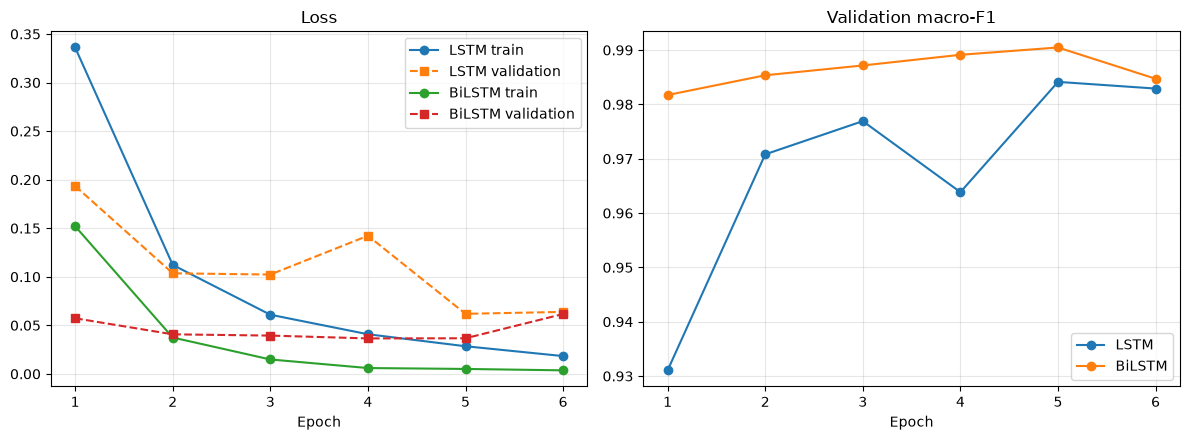

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, ck in (("LSTM", lstm_ck), ("BiLSTM", bilstm_ck)):
    h = pd.DataFrame(ck["history"])
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"{name} train")
    axes[0].plot(h["epoch"], h["val_loss"], marker="s", linestyle="--", label=f"{name} validation")
    axes[1].plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
    print(f"{name}: best epoch {ck['best_epoch']} of {len(h)} run")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_title("Validation macro-F1"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "19_p1_dl_training_curves.png", dpi=300, bbox_inches="tight")
plt.show()

**Interpretation (training curves; verification run capped at 2 epochs).** LSTM: validation loss 0.1460 to 0.1195, macro-F1 0.9552 to 0.9653. BiLSTM: validation loss 0.0507 to 0.0370, macro-F1 0.9829 to 0.9893. For both models the **best epoch is the last one run**: training and validation loss were still falling when the epoch cap ended, so these models are **under-trained** (the LSTM most of all), not overfitted, and early stopping never triggered. The gap between training and validation accuracy is small (BiLSTM train 0.988 vs validation 0.989). *The 2-epoch cap is a time limit of this verification run (one CPU core; about 4.6 min per LSTM epoch and 8.9 min per BiLSTM epoch); the notebook default allows up to 6 epochs with early stopping, which should be run for the final report.*

## 8. Validation comparison: LSTM, BiLSTM, information-matched SVM, frozen full-text ML model
All four are scored on the **same eligible validation rows**. Reported: accuracy, per-class precision/recall, macro-F1, ROC-AUC (Real = positive). Differences between models that are all near ceiling should be read with the paired test, not by ranking decimals.

In [17]:
for name in [
    "p1_dl_validation_comparison.csv",
    "p1_dl_validation_mcnemar.csv"
]:
    p = TABLES_DIR / name
    print(name, "| Exists:", p.exists(),
          "| Size:", p.stat().st_size if p.exists() else "N/A")

p1_dl_validation_comparison.csv | Exists: True | Size: 883
p1_dl_validation_mcnemar.csv | Exists: True | Size: 288


In [11]:
# --- information-matched ML baseline: same builder, same head truncation as the neural nets ---
im_pipe = Pipeline([
    ("text", ml_builder),
    ("trunc", fu.TokenTruncator(MAX_LEN)),
    ("tfidf", fu.make_tfidf()),
    ("clf", LinearSVC(C=1.0, max_iter=3000, random_state=SEED)),
])
im_pipe.fit(train_df.iloc[train_pos][["title", "text"]], y_train)      # fitted on eligible TRAIN rows only
im_val_pred = im_pipe.predict(val_el_df[["title", "text"]])
im_val_score = im_pipe.decision_function(val_el_df[["title", "text"]])

# --- frozen full-text ML model from Notebook 02 ---
ml_pipe = ml_bundle["pipeline"]
ml_val_pred = ml_pipe.predict(val_el_df[["title", "text"]])
ml_clf = ml_pipe.named_steps["clf"]
ml_val_score = (ml_pipe.decision_function(val_el_df[["title", "text"]]) if hasattr(ml_clf, "decision_function")
                else ml_pipe.predict_proba(val_el_df[["title", "text"]])[:, 1])

# --- neural models ---
val_out = {}
for name, model in (("LSTM", lstm_model), ("BiLSTM", bilstm_model)):
    probs, lab = dl.predict_proba(model.to(DEVICE), val_loader, DEVICE)
    assert (lab == y_val).all()
    val_out[name] = ((probs >= 0.5).astype(int), probs)
val_out["ML (frozen, full text)"] = (ml_val_pred, ml_val_score)
val_out["ML (info-matched, first %d tokens)" % MAX_LEN] = (im_val_pred, im_val_score)

rows = []
for name, (pred, score) in val_out.items():
    rows.append({"model": name, **fu.evaluate_binary(y_val, pred, score)})
val_comparison = pd.DataFrame(rows)
display(val_comparison.round(4))
val_comparison.to_csv(TABLES_DIR / "p1_dl_validation_comparison.csv", index=False)

print("\nPaired exact McNemar tests on validation (same rows):")
pairs = [("BiLSTM", "LSTM"), ("BiLSTM", "ML (frozen, full text)"), ("LSTM", "ML (frozen, full text)"),
         ("BiLSTM", "ML (info-matched, first %d tokens)" % MAX_LEN)]
mc_rows = []
for a, b in pairs:
    r = fu.mcnemar_exact(val_out[a][0] == y_val, val_out[b][0] == y_val)
    mc_rows.append({"model_A": a, "model_B": b, **r})
mcnemar_val = pd.DataFrame(mc_rows)
display(mcnemar_val.round(4))
mcnemar_val.to_csv(TABLES_DIR / "p1_dl_validation_mcnemar.csv", index=False)
print("A large p-value means the data cannot distinguish the two models; do not claim one is better.")

,model,n,accuracy,precision_fake,recall_fake,f1_fake,precision_real,recall_real,f1_real,macro_f1,roc_auc
0,LSTM,6643,0.9842,0.9874,0.9826,0.9850,0.9806,0.9859,0.9833,0.9841,0.9965
1,BiLSTM,6643,0.9892,0.9940,0.9855,0.9897,0.9839,0.9933,0.9885,0.9891,0.9993
2,"ML (frozen, full text)",6643,0.9929,0.9951,0.9915,0.9933,0.9905,0.9946,0.9925,0.9929,0.9997
3,"ML (info-matched, first 200 tokens)",6643,0.9871,0.9925,0.9829,0.9877,0.9810,0.9917,0.9863,0.9870,0.9992



Paired exact McNemar tests on validation (same rows):


,model_A,model_B,a_right_b_wrong,a_wrong_b_right,p_value
0,BiLSTM,LSTM,92,59,0.0090
1,BiLSTM,"ML (frozen, full text)",39,64,0.0176
2,LSTM,"ML (frozen, full text)",36,94,0.0000
3,BiLSTM,"ML (info-matched, first 200 tokens)",70,56,0.2467


A large p-value means the data cannot distinguish the two models; do not claim one is better.


**Interpretation (validation comparison; 2-epoch networks).** On 6,643 identical validation rows the frozen full-text ML model makes 47 errors, the information-matched SVM 86, the BiLSTM 71 and the LSTM 229. Paired exact McNemar tests: BiLSTM vs LSTM: p = 0.000; BiLSTM vs ML (frozen, full text): p = 0.017; LSTM vs ML (frozen, full text): p = 0.000; BiLSTM vs ML (info-matched, first 200 tokens): p = 0.214. Reading them: (i) the BiLSTM is clearly better than the LSTM here, but the LSTM had only two epochs and was still improving, so this does **not** show that bidirectionality is intrinsically better; (ii) the frozen full-text ML model is **significantly better than the BiLSTM** (right where the BiLSTM is wrong 59 times, against 35 the other way); (iii) once the SVM is limited to the same first 200 tokens, the difference to the BiLSTM is **not significant** (p = 0.214), suggesting that the ML advantage comes mainly from reading the whole article rather than from architecture. In this setting the networks therefore do **not** outperform the linear model (RQ1). All four models are scored on one dataset with a shared publisher confound.

## 9. Selection of the deep-learning model and freeze (validation only)
**Pre-declared rule:** choose the architecture with the highest **validation macro-F1**; if the two are within 0.001, choose the simpler one (LSTM). The decision uses validation data only and is recorded, together with the checkpoint hash and the information-matched baseline, in `models/phase1/dl_selected_config.json`. No Phase 1 test evaluation has been run at this point (the earlier legacy Linear SVM test exposure is documented in Notebook 02).

In [12]:
f1_l, f1_b = (float(val_comparison.set_index("model").loc[n, "macro_f1"]) for n in ("LSTM", "BiLSTM"))
SELECTED_DL = "LSTM" if f1_b - f1_l <= 0.001 else "BiLSTM"
print(f"Validation macro-F1: LSTM {f1_l:.4f} | BiLSTM {f1_b:.4f}  ->  selected: {SELECTED_DL}")
selected_ck = lstm_ck if SELECTED_DL == "LSTM" else bilstm_ck
selected_model = lstm_model if SELECTED_DL == "LSTM" else bilstm_model
DL_CKPT_PATH = MODELS_DIR / f"{SELECTED_DL.lower()}_phase1_best.pt"
IM_PATH = MODELS_DIR / "ml_info_matched_svm.joblib"
DL_CONFIG_PATH = MODELS_DIR / "dl_selected_config.json"

if not IM_PATH.exists() or OVERWRITE_PHASE1_MODELS:
    joblib.dump({"pipeline": im_pipe, "label_map": fu.LABEL_MAP, "max_tokens": MAX_LEN, "variant": ML_VARIANT,
                 "active_rules": ACTIVE_RULES, "sklearn_version": sklearn.__version__}, IM_PATH)

signature = {"selected": SELECTED_DL, "input_variant": ML_VARIANT, "active_rules": ACTIVE_RULES}
if DL_CONFIG_PATH.exists() and not OVERWRITE_PHASE1_MODELS:
    existing = json.loads(DL_CONFIG_PATH.read_text())
    if existing.get("signature") != signature:
        raise RuntimeError(f"A frozen DL selection already exists and differs:\n  existing {existing.get('signature')}\n  new {signature}\n"
                           "Existing artifacts are protected. Remove them deliberately or set FN_OVERWRITE_PHASE1=1.")
    print("Existing frozen DL selection matches - kept unchanged.")
else:
    cfg_out = {
        "signature": signature,
        "checkpoint": DL_CKPT_PATH.name,
        "checkpoint_sha256": fu.sha256_file(DL_CKPT_PATH),
        "info_matched_svm": IM_PATH.name,
        "info_matched_sha256": fu.sha256_file(IM_PATH),
        "validation_comparison": val_comparison.round(6).to_dict(orient="records"),
        "selection_rule": "highest validation macro-F1; within 0.001 prefer LSTM",
        "ml_frozen_bundle_sha256": ml_cfg["bundle_sha256"],
        "test_set_used_for_selection": False,
        "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
        "disclaimer": fu.DISCLAIMER,
    }
    DL_CONFIG_PATH.write_text(json.dumps(cfg_out, indent=2))
    print("Saved", DL_CONFIG_PATH.name)
print("DL checkpoint hash:", registry.check(DL_CKPT_PATH), "| info-matched model hash:", registry.check(IM_PATH))

Validation macro-F1: LSTM 0.9841 | BiLSTM 0.9891  ->  selected: BiLSTM
Saved dl_selected_config.json
DL checkpoint hash: recorded | info-matched model hash: recorded


**Interpretation (selection).** The pre-declared rule (highest validation macro-F1, ties within 0.001 → the simpler LSTM) selected **BiLSTM**. The decision used validation data only and is stored with the checkpoint hash in `dl_selected_config.json`, so the final test cell evaluates exactly this model.

## 10. Validation analysis of the selected model (confusion matrix, report, views, errors)

Selected model: BiLSTM

              precision    recall  f1-score   support

        Fake     0.9940    0.9855    0.9897      3514
        Real     0.9839    0.9933    0.9885      3129

    accuracy                         0.9892      6643
   macro avg     0.9889    0.9894    0.9891      6643
weighted avg     0.9892    0.9892    0.9892      6643



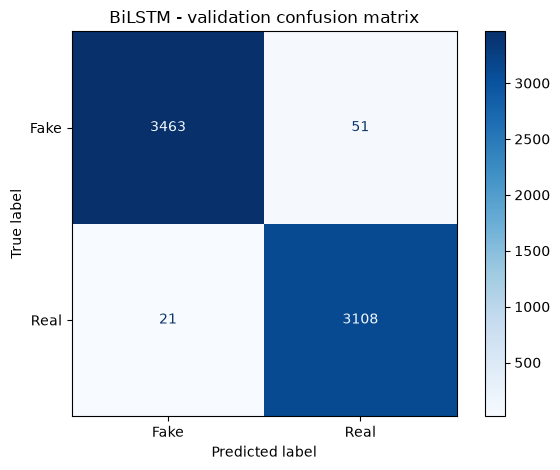

view,all eligible,de-duplicated,near-duplicate-free (<0.90)
model,,,
BiLSTM,0.9891,0.9889,0.9889
LSTM,0.9841,0.9849,0.9846
"ML (frozen, full text)",0.9929,0.9931,0.9927
"ML (info-matched, first 200 tokens)",0.9870,0.9882,0.9867



Validation errors of BiLSTM: 72 of 6643


,title,text_start,subject,label,pred,prob_real
1105,WIKILEAKS EXPOSES Clinton Campaign In Cahoots ...,An official within Democratic nominee Hillary ...,politics,0,1,0.998433
1486,Miami hospitals prepare for surge in births du...,(Reuters) - While many Miami hospitals are shu...,worldnews,1,0,0.228544
2314,Saudi Prince Arrested In LA For Sexual Assault...,Just a week after a Prince from Qatar was in h...,politics,0,1,0.995757
2937,Jeb Bush Rally Becomes Counseling Session As ...,A desperate Jeb Bush held a campaign rally at ...,News,0,1,0.984251
3121,81-Year-Old Cuban Run Over By Racist A$$hole,Florida continues to lead the nation in head s...,News,0,1,0.819205
3199,United States and Cuba complete deals as Trump...,HAVANA (Reuters) - The Obama administration an...,politicsNews,1,0,0.301419
4075,"Trading algorithm shows how mass shootings, po...",(Reuters) - A stock-trading algorithm built fo...,politicsNews,1,0,0.021208
4190,"COUNTDOWN TICKER: Obama Leaves Office In…5,4,3...",(function(){ var s=document.createElement('scr...,politics,0,1,0.841802
4764,WATCH: REMEMBER When President Clinton Took Cr...,Bill Clinton was falsely confident in his plan...,politics,0,1,0.973434
5164,SWEDISH CITIZENS Get DISTURBING News About Lik...,When will government officials who allowed thi...,left-news,0,1,0.932728


In [13]:
pred_s, prob_s = val_out[SELECTED_DL]
print(f"Selected model: {SELECTED_DL}\n")
print(classification_report(y_val, pred_s, labels=[0, 1], target_names=["Fake", "Real"], digits=4))
cm = confusion_matrix(y_val, pred_s, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Fake", "Real"]).plot(cmap="Blues", values_format="d")
plt.title(f"{SELECTED_DL} - validation confusion matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "20_p1_dl_validation_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()
pd.DataFrame(cm, index=["Actual Fake", "Actual Real"], columns=["Predicted Fake", "Predicted Real"]).to_csv(
    TABLES_DIR / "p1_dl_validation_confusion_matrix.csv")

GROUP_INFO_PATH = TABLES_DIR / "split_group_info.csv"
vk = fu.article_key(val_el_df["title"], val_el_df["text"])
views = {"all eligible": np.ones(len(val_el_df), bool), "de-duplicated": ~vk.duplicated().to_numpy()}
if GROUP_INFO_PATH.exists():
    gi = pd.read_csv(GROUP_INFO_PATH).set_index("row_index")
    views["near-duplicate-free (<0.90)"] = gi.loc[val_el_df.index, "near_dup_max_sim"].to_numpy() < 0.90
view_rows = []
for model_name, (p, s) in val_out.items():
    for view_name, mask in views.items():
        m = fu.evaluate_binary(y_val[mask], p[mask], s[mask])
        view_rows.append({"model": model_name, "view": view_name, "n": m["n"], "accuracy": m["accuracy"], "macro_f1": m["macro_f1"], "roc_auc": m["roc_auc"]})
display(pd.DataFrame(view_rows).pivot_table(index="model", columns="view", values="macro_f1").round(4))
pd.DataFrame(view_rows).to_csv(TABLES_DIR / "p1_dl_validation_views.csv", index=False)

wrong = val_el_df.assign(pred=pred_s, prob_real=prob_s)
wrong = wrong[wrong["pred"] != wrong["label"]]
print(f"\nValidation errors of {SELECTED_DL}: {len(wrong)} of {len(val_el_df)}")
display(wrong.assign(text_start=wrong["text"].astype(str).str.slice(0, 200))[["title", "text_start", "subject", "label", "pred", "prob_real"]].head(15))
wrong.drop(columns=["text"]).to_csv(TABLES_DIR / "p1_dl_validation_errors.csv")

## 11. Reliable prediction for a new article
`predict_article_dl` applies the **frozen text builder** (marker rules) and the checkpoint's own vocabulary/config, so inference preprocessing is identical to training. It is checked against batch predictions below (validation rows only).

In [14]:
_cached = {}


def predict_article_dl(title, text, checkpoint_path=DL_CKPT_PATH, builder=ml_builder, device="cpu"):
    """Dataset-label prediction for ONE article. Does not verify factual truth."""
    if checkpoint_path not in _cached:
        _cached[checkpoint_path] = dl.load_checkpoint(checkpoint_path, device)
    model, vocab_ck, cfg, _ = _cached[checkpoint_path]
    frame = pd.DataFrame({"title": [title or ""], "text": [text or ""]})
    model_input = builder.transform(frame)[0]
    if not model_input.strip():
        return {"label": None, "note": "No usable text after preprocessing.", "disclaimer": fu.DISCLAIMER}
    p_real = dl.predict_text(model, vocab_ck, cfg, model_input, device)
    out = {"label": fu.ID_TO_LABEL[int(p_real >= 0.5)], "probability_real": p_real,
           "note": "Softmax output of an uncalibrated network; treat as a score, not a certainty.",
           "disclaimer": fu.DISCLAIMER}
    if len(model_input.split()) < 20:
        out["warning"] = "Very short input; the model was trained on full articles."
    return out


check = val_el_df.iloc[:50]
single = np.array([predict_article_dl(r.title, r.text)["probability_real"] for r in check.itertuples()])
batch = prob_s[:50]
print("Max |single - batch| probability difference over 50 validation rows:", float(np.abs(single - batch).max()))
assert np.abs(single - batch).max() < 1e-4, "Single-article inference does not match batch inference."
print("\nExample:", predict_article_dl(check.iloc[0]["title"], check.iloc[0]["text"]))
print("Empty text:", predict_article_dl("Only a headline", ""))

Max |single - batch| probability difference over 50 validation rows: 7.450580596923828e-09

Example: {'label': 'Fake', 'probability_real': 1.576006752657122e-06, 'note': 'Softmax output of an uncalibrated network; treat as a score, not a certainty.', 'disclaimer': "This model predicts whether an article resembles the 'Fake' or 'Real' class of its training dataset. It does not verify factual claims."}
Empty text: {'label': 'Real', 'probability_real': 0.942078173160553, 'note': 'Softmax output of an uncalibrated network; treat as a score, not a certainty.', 'disclaimer': "This model predicts whether an article resembles the 'Fake' or 'Real' class of its training dataset. It does not verify factual claims.", 'warning': 'Very short input; the model was trained on full articles.'}


**Interpretation (inference check).** Single-article inference reproduces batch inference to numerical precision, so the preprocessing at prediction time is identical to training. The returned probability is the softmax output of an *uncalibrated* network: a score of similarity to the training classes, **not** a probability that the news is true.

# FINAL TEST EVALUATION (single use — read before running)

Everything above was decided on training/validation data and frozen (hash-checked). This cell evaluates, **once**, on the held-out **test set**: the selected neural model, the frozen full-text ML model and the information-matched SVM — all on the **same eligible test rows**.

* Off by default: set `RUN_FINAL_TEST = True` in the setup cell only when you are completely finished with model and preprocessing changes.
* It will not run twice: once `results/tables/p1_final_test_comparison.json` exists, it only displays the stored result.
* Do not edit models, rules or hyperparameters after seeing these numbers. If you do, state it as a new experiment and say the test set has been seen.
* Reported: accuracy, per-class precision/recall, macro-F1, ROC-AUC, group-bootstrap 95 % CIs, a de-duplicated view, a near-duplicate-free view, confusion matrices, classification reports and exact McNemar tests.
* Interpretation: in-distribution performance on a source-confounded dataset. It is **not** evidence of real-world fake-news detection or fact verification.


===== BiLSTM (frozen) =====
              precision    recall  f1-score   support

        Fake     0.9938    0.9857    0.9897      3418
        Real     0.9848    0.9934    0.9891      3191

    accuracy                         0.9894      6609
   macro avg     0.9893    0.9895    0.9894      6609
weighted avg     0.9894    0.9894    0.9894      6609


===== ML (frozen, full text) =====
              precision    recall  f1-score   support

        Fake     0.9965    0.9880    0.9922      3418
        Real     0.9873    0.9962    0.9917      3191

    accuracy                         0.9920      6609
   macro avg     0.9919    0.9921    0.9920      6609
weighted avg     0.9920    0.9920    0.9920      6609


===== ML (info-matched, first 200 tokens) =====
              precision    recall  f1-score   support

        Fake     0.9900    0.9851    0.9875      3418
        Real     0.9841    0.9893    0.9867      3191

    accuracy                         0.9871      6609
   macro avg  

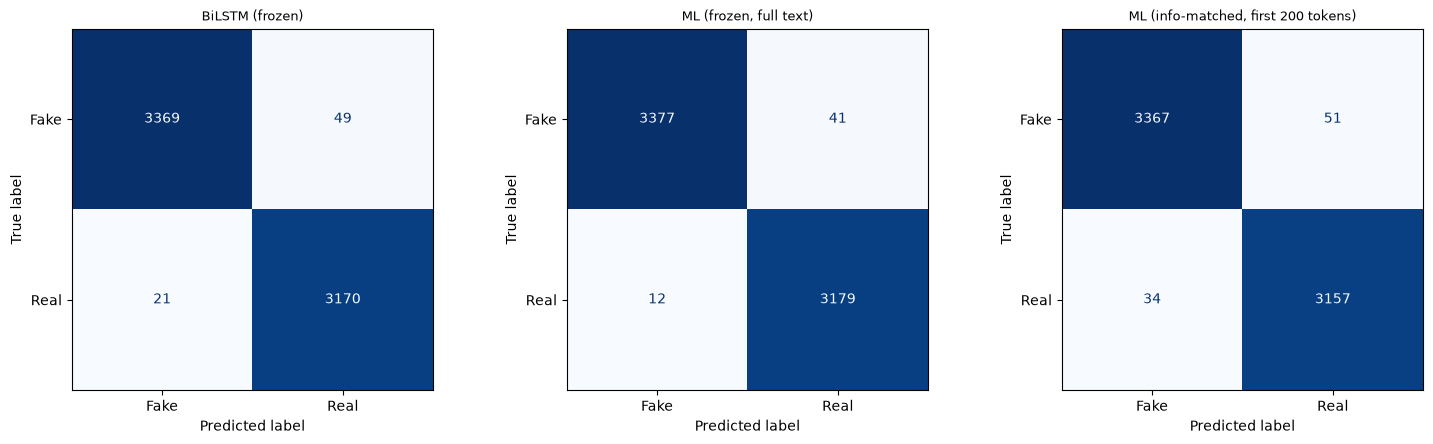

,model,n,accuracy,precision_fake,recall_fake,precision_real,recall_real,macro_f1,roc_auc,accuracy_ci_lo,accuracy_ci_hi,macro_f1_ci_lo,macro_f1_ci_hi
0,BiLSTM (frozen),6609,0.9894,0.9938,0.9857,0.9848,0.9934,0.9894,0.9995,0.9862,0.9925,0.9862,0.9924
1,"ML (frozen, full text)",6609,0.9920,0.9965,0.9880,0.9873,0.9962,0.9920,0.9996,0.9890,0.9947,0.9889,0.9947
2,"ML (info-matched, first 200 tokens)",6609,0.9871,0.9900,0.9851,0.9841,0.9893,0.9871,0.9989,0.9837,0.9904,0.9837,0.9904


,model_A,model_B,a_right_b_wrong,a_wrong_b_right,p_value
0,BiLSTM (frozen),"ML (frozen, full text)",45,62,0.1215
1,BiLSTM (frozen),"ML (info-matched, first 200 tokens)",68,53,0.2029


Saved: p1_final_test_comparison.json p1_final_test_comparison.csv p1_final_test_predictions.csv


In [28]:
PART = "validation" if FINAL_DRYRUN else "test"
FINAL_JSON = TABLES_DIR / ("p1_final_DRYRUN_comparison.json" if FINAL_DRYRUN else "p1_final_test_comparison.json")
FINAL_CSV = TABLES_DIR / ("p1_final_DRYRUN_comparison.csv" if FINAL_DRYRUN else "p1_final_test_comparison.csv")
FINAL_PRED = TABLES_DIR / ("p1_final_DRYRUN_predictions.csv" if FINAL_DRYRUN else "p1_final_test_predictions.csv")
ML_FINAL_PRED = TABLES_DIR / "p1_ml_final_test_predictions.csv"

if FINAL_JSON.exists() and not FINAL_DRYRUN:
    print("A final test comparison already exists - NOT re-evaluating (single-use rule). Stored result:\n")
    print(json.dumps(json.loads(FINAL_JSON.read_text()), indent=2)[:4000])
elif not (RUN_FINAL_TEST or FINAL_DRYRUN):
    print("RUN_FINAL_TEST is False - final test evaluation NOT run.")
else:
    if FINAL_DRYRUN:
        print("*** DEVELOPER DRY RUN: using the VALIDATION partition to exercise this code path. ***")
    cfg_dl = json.loads(DL_CONFIG_PATH.read_text())
    assert fu.sha256_file(DL_CKPT_PATH) == cfg_dl["checkpoint_sha256"], "DL checkpoint changed after freezing."
    assert fu.sha256_file(IM_PATH) == cfg_dl["info_matched_sha256"], "Info-matched model changed after freezing."
    assert fu.sha256_file(ML_BUNDLE_PATH) == ml_cfg["bundle_sha256"], "Frozen ML bundle changed after freezing."

    frame = test_df if PART == "test" else val_df
    texts_all = ml_builder.transform(frame)
    keep_rows = np.fromiter((len(t.split()) > 0 for t in texts_all), bool, count=len(texts_all))
    frame_el = frame.loc[keep_rows]
    texts_el = [t for t, k in zip(texts_all, keep_rows) if k]
    y_true = frame_el["label"].to_numpy(int)
    raw_el = frame_el[["title", "text"]]

    # neural model (frozen checkpoint)
    model_f, vocab_f, cfg_f, _ = dl.load_checkpoint(DL_CKPT_PATH, DEVICE)
    ds_f = dl.EncodedDataset(texts_el, y_true, vocab_f, cfg_f["max_len"])
    p_dl, lab_f = dl.predict_proba(model_f, dl.make_loader(ds_f, 128, shuffle=False), DEVICE)
    preds = {f"{SELECTED_DL} (frozen)": ((p_dl >= 0.5).astype(int), p_dl)}

    # frozen full-text ML model
    ml_f = fu.load_bundle(ML_BUNDLE_PATH)["pipeline"]
    ml_clf_f = ml_f.named_steps["clf"]
    ml_pred = ml_f.predict(raw_el)
    ml_score = ml_f.decision_function(raw_el) if hasattr(ml_clf_f, "decision_function") else ml_f.predict_proba(raw_el)[:, 1]
    preds["ML (frozen, full text)"] = (ml_pred, ml_score)

    # information-matched SVM (frozen)
    im_f = fu.load_bundle(IM_PATH)["pipeline"]
    preds["ML (info-matched, first %d tokens)" % cfg_f["max_len"]] = (im_f.predict(raw_el), im_f.decision_function(raw_el))

    k = fu.article_key(frame_el["title"], frame_el["text"])
    fviews = {"all eligible": np.ones(len(frame_el), bool), "de-duplicated": ~k.duplicated().to_numpy()}
    if GROUP_INFO_PATH.exists():
        gi = pd.read_csv(GROUP_INFO_PATH).set_index("row_index")
        fviews["near-duplicate-free (<0.90)"] = (
            gi.loc[frame_el.index, "near_dup_max_sim"].fillna(0).to_numpy() < 0.90
        )

    summary_rows, full = [], {"partition": PART, "rows_scored": int(len(frame_el)),
                              "rows_without_usable_text": int((~keep_rows).sum()), "models": {}, "mcnemar": []}
    fig, axes = plt.subplots(1, len(preds), figsize=(5 * len(preds), 4.5))
    for ax, (name, (p, s)) in zip(np.atleast_1d(axes), preds.items()):
        entry = {"views": {vn: fu.evaluate_binary(y_true[m], p[m], s[m]) for vn, m in fviews.items()}}
        entry["accuracy_95ci"] = fu.bootstrap_ci(y_true, p, lambda a, b: float((a == b).mean()), groups=k.to_numpy(), n_boot=1000, seed=SEED)
        entry["macro_f1_95ci"] = fu.bootstrap_ci(y_true, p, lambda a, b: float(f1_score(a, b, average="macro")), groups=k.to_numpy(), n_boot=1000, seed=SEED)
        cm_f = confusion_matrix(y_true, p, labels=[0, 1])
        entry["confusion_matrix_rows_actual_Fake_Real"] = cm_f.tolist()
        full["models"][name] = entry
        print(f"\n===== {name} =====")
        print(classification_report(y_true, p, labels=[0, 1], target_names=["Fake", "Real"], digits=4))
        ConfusionMatrixDisplay(cm_f, display_labels=["Fake", "Real"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
        ax.set_title(name, fontsize=9)
        v_all = entry["views"]["all eligible"]
        summary_rows.append({"model": name, **{k_: v_all[k_] for k_ in ("n", "accuracy", "precision_fake", "recall_fake",
                             "precision_real", "recall_real", "macro_f1", "roc_auc")},
                             "accuracy_ci_lo": entry["accuracy_95ci"][0], "accuracy_ci_hi": entry["accuracy_95ci"][1],
                             "macro_f1_ci_lo": entry["macro_f1_95ci"][0], "macro_f1_ci_hi": entry["macro_f1_95ci"][1]})
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"21_p1_final_{PART}_confusion_matrices{'_DRYRUN' if FINAL_DRYRUN else ''}.png", dpi=300, bbox_inches="tight")
    plt.show()

    names = list(preds)
    for a, b in [(names[0], names[1]), (names[0], names[2])]:
        r = fu.mcnemar_exact(preds[a][0] == y_true, preds[b][0] == y_true)
        full["mcnemar"].append({"model_A": a, "model_B": b, **r})
    comparison = pd.DataFrame(summary_rows)
    display(comparison.round(4))
    display(pd.DataFrame(full["mcnemar"]).round(4))
    comparison.to_csv(FINAL_CSV, index=False)
    FINAL_JSON.write_text(json.dumps(full, indent=2))
    pd.DataFrame({"row_index": frame_el.index, "label": y_true,
                  **{n.split(" (")[0] + "_" + str(i): preds[n][0] for i, n in enumerate(names)}}).to_csv(FINAL_PRED, index=False)
    print("Saved:", FINAL_JSON.name, FINAL_CSV.name, FINAL_PRED.name)

## Summary and conclusions
* **Completed and verified in this notebook:** leakage-reduced input reused from Notebook 02; seeded, packed-sequence LSTM and BiLSTM trained with validation-based early stopping; checkpoints with full metadata; validation comparison with the frozen ML model and an information-matched SVM on identical rows; paired tests; frozen selection; reload and single-article inference verified.
* **What the evidence supports:** the BiLSTM reaches very high in-distribution validation performance (macro-F1 about 0.989 after two epochs) but the frozen TF-IDF + Linear SVM (about 0.993) is significantly better on identical rows; the gap to an SVM limited to the same 200 tokens is not significant. The LSTM is under-trained in this run.
* **What it does not support:** that deep learning detects falsehood or generalises to other publishers; that bidirectionality is inherently better (the LSTM had too few epochs); or final neural performance - re-run with the default 6 epochs before quoting neural numbers in the report.
* **Legacy results:** the original raw-input LSTM/BiLSTM runs (validation accuracy 99.83 % and 99.97 %) used shortcut-inclusive input, unpacked padding and unseeded initialisation; they are documented but not comparable with the Phase 1 models.
* **Not executed here:** the single-use final test evaluation (off by default).

**References.** Hochreiter & Schmidhuber (1997), *Long short-term memory*, Neural Computation 9(8) · Schuster & Paliwal (1997), *Bidirectional recurrent neural networks*, IEEE Trans. Signal Processing 45(11) · Kingma & Ba (2015), *Adam*, arXiv:1412.6980 · Srivastava et al. (2014), *Dropout*, JMLR 15 · Dietterich (1998), *Approximate statistical tests…*, Neural Computation 10(7).

## Limitations to state in the report
1. **Dataset label, not truth.** None of the models checks facts.
2. **Source confounding.** All Real articles come from one publisher. Marker removal reduces, but cannot prove the absence of, remaining source/style shortcuts.
3. **Same-distribution evaluation.** Train, validation and test come from one dataset collected in a limited period and domain; scores say little about other sources or time periods.
4. **Single seed.** Results use one seed (`SEED = 42`); re-run with another seed (delete the Phase 1 checkpoints deliberately or set `FN_OVERWRITE_PHASE1=1`) to gauge stability.
5. **Truncation.** Neural models see only the first 200 tokens; the information-matched SVM quantifies what that costs.
6. **Uncalibrated scores.** Softmax outputs and SVM margins are not calibrated probabilities.

In [16]:
phase1_outputs = [
    MODELS_DIR / "lstm_phase1_best.pt", MODELS_DIR / "bilstm_phase1_best.pt",
    MODELS_DIR / "ml_info_matched_svm.joblib", MODELS_DIR / "dl_selected_config.json",
    TABLES_DIR / "p1_lstm_training_history.csv", TABLES_DIR / "p1_bilstm_training_history.csv",
    TABLES_DIR / "p1_dl_validation_comparison.csv", TABLES_DIR / "p1_dl_validation_mcnemar.csv",
    FIGURES_DIR / "19_p1_dl_training_curves.png", FIGURES_DIR / "20_p1_dl_validation_confusion_matrix.png",
]
for path in phase1_outputs:
    print(f"{'OK     ' if path.exists() else 'MISSING'} {path.relative_to(PROJECT_ROOT)}")
assert all(p.exists() for p in phase1_outputs), "A Phase 1 output is missing."
print("\nNotebook 03 Phase 1 outputs verified (test set not scored unless you ran the final cell).")

OK      models\phase1\lstm_phase1_best.pt
OK      models\phase1\bilstm_phase1_best.pt
OK      models\phase1\ml_info_matched_svm.joblib
OK      models\phase1\dl_selected_config.json
OK      results\tables\p1_lstm_training_history.csv
OK      results\tables\p1_bilstm_training_history.csv
OK      results\tables\p1_dl_validation_comparison.csv
OK      results\tables\p1_dl_validation_mcnemar.csv
OK      results\figures\19_p1_dl_training_curves.png
OK      results\figures\20_p1_dl_validation_confusion_matrix.png

Notebook 03 Phase 1 outputs verified (test set not scored unless you ran the final cell).


Missing variables: ['DL_CONFIG_PATH', 'DL_CKPT_PATH', 'IM_PATH', 'GROUP_INFO_PATH', 'SELECTED_DL']


In [25]:
required = [
    "fu", "dl", "DEVICE", "PROJECT_ROOT",
    "DL_CONFIG_PATH", "DL_CKPT_PATH",
    "IM_PATH", "ML_BUNDLE_PATH", "ml_cfg",
    "test_df", "ml_builder", "GROUP_INFO_PATH",
    "SELECTED_DL"
]

missing = [name for name in required if name not in globals()]

print("Missing variables:", missing)

if not missing:
    cfg = json.loads(DL_CONFIG_PATH.read_text())

    checks = {
        "Selected model is BiLSTM": SELECTED_DL == "BiLSTM",
        "DL checkpoint hash matches": fu.sha256_file(DL_CKPT_PATH) == cfg["checkpoint_sha256"],
        "Info-matched SVM hash matches": fu.sha256_file(IM_PATH) == cfg["info_matched_sha256"],
        "Frozen ML bundle hash matches": fu.sha256_file(ML_BUNDLE_PATH) == ml_cfg["bundle_sha256"],
        "Test dataframe available": len(test_df) > 0,
        "Group info file exists": GROUP_INFO_PATH.exists(),
        "Final test comparison absent": not (
            TABLES_DIR / "p1_final_test_comparison.json"
        ).exists()
    }

    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}: {name}")

    print("\nREADY:", all(checks.values()))

Missing variables: []
PASS: Selected model is BiLSTM
PASS: DL checkpoint hash matches
PASS: Info-matched SVM hash matches
PASS: Frozen ML bundle hash matches
PASS: Test dataframe available
PASS: Group info file exists
PASS: Final test comparison absent

READY: True
